# 05 · Sensibilidad y síntesis final

**Proyecto semestral IMT2200, Grupo 5:** *¿Mide el NEM lo mismo para todos?*

**Entrada:** `data/processed/muestra.parquet`. Sensibilidad de las Hipótesis 1 y 2,
revisión de un k-means de colegios, síntesis final y fuentes.

In [1]:
# Librerías, funciones del proyecto (src/) y carga de datos.
import sys

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf
from scipy.cluster.vq import kmeans2

sys.path.insert(0, '..')  # para importar src/ desde notebooks/
from src.funciones import (coeficientes, contraste,  # noqa: E402
                           estandarizar, icc, mostrar, odds_ratios,
                           preparar_datos)

acceso = preparar_datos(pd.read_parquet('../data/processed/muestra.parquet'))
# Igual que en 03: los modelos jerárquicos excluyen a los 4 estudiantes sin
# decil medio del colegio.
datos = acceso[acceso['decil_medio_colegio'].notna()]

## 1. Sensibilidad del modelo jerárquico (Hipótesis 1)

Se repite el modelo principal de `03_modelamiento` cambiando una cosa a la vez:

- **Lectora** y **Matemática 1** en vez de la electiva: NEM y PAES se estandarizan
  dentro de cada año entre quienes rindieron esa prueba (no hay grupos de electiva).
- **Sin el grupo Ambas:** solo quienes rindieron una electiva.
- **Sin modalidad:** para ver si el coeficiente de técnico-profesional (-0,19) afecta
  a las dependencias.

En el modelo con Matemática 1, el optimizador por defecto de `statsmodels` no
converge; se usa el método de Powell, que sí converge y sin avisos.

In [2]:
# 1.a Variantes del modelo: (nombre, datos, fórmula).
CONTROLES = ' + C(ANIO) + dependencia + decil + sexo + modalidad'
PRINCIPAL = 'NEM_z ~ PAES_z * electiva' + CONTROLES

# Con Lectora o M1, NEM y PAES se estandarizan dentro de cada año entre
# quienes rindieron esa prueba.
lectora = datos[datos['CLEC_1ra'].notna()].copy()
lectora['NEM_alt'] = estandarizar(lectora, 'PTJE_NEM', ['ANIO'])
lectora['PAES_alt'] = estandarizar(lectora, 'CLEC_1ra', ['ANIO'])
mate1 = datos[datos['MATE1_1ra'].notna()].copy()
mate1['NEM_alt'] = estandarizar(mate1, 'PTJE_NEM', ['ANIO'])
mate1['PAES_alt'] = estandarizar(mate1, 'MATE1_1ra', ['ANIO'])

variantes = [
    ('principal (electiva)', datos, PRINCIPAL),
    ('sin Ambas', datos[datos['electiva'] != 'Ambas'], PRINCIPAL),
    ('sin modalidad', datos, PRINCIPAL.replace(' + modalidad', '')),
    ('Lectora', lectora, 'NEM_alt ~ PAES_alt' + CONTROLES),
    ('Matemática 1', mate1, 'NEM_alt ~ PAES_alt' + CONTROLES),
]

In [3]:
# 1.b Ajusta cada variante y resume dependencia, contraste SLEP - Municipal
# e ICC residual.
filas = {}
slep = {}
for nombre, d, formula in variantes:
    modelo = smf.mixedlm(formula, d, groups=d['RBD'])
    if nombre == 'Matemática 1':
        resultado = modelo.fit(method='powell')  # el de defecto no converge
    else:
        resultado = modelo.fit()
    tabla = coeficientes(resultado)
    dif = contraste(resultado, 'dependencia[T.SLEP]',
                    'dependencia[T.Municipal]')
    filas[nombre] = {'n': len(d), 'convergió': resultado.converged,
                     'ICC residual': icc(resultado)}
    for termino in tabla.filter(like='dependencia', axis=0).index:
        filas[nombre][termino] = tabla.loc[termino, 'coef']
    filas[nombre]['SLEP - Municipal'] = dif['diferencia']
    filas[nombre]['IC inf.'] = dif['ic95_inf']
    filas[nombre]['IC sup.'] = dif['ic95_sup']
    slep[nombre] = tabla.loc['dependencia[T.SLEP]']
display(pd.DataFrame.from_dict(filas, orient='index').round(3))

,n,convergió,ICC residual,dependencia[T.Adm. delegada],dependencia[T.Municipal],dependencia[T.Part. pagado],dependencia[T.SLEP],SLEP - Municipal,IC inf.,IC sup.
principal (electiva),654138,True,0.139,0.083,0.112,-0.071,0.173,0.061,0.045,0.078
sin Ambas,462655,True,0.138,0.089,0.090,-0.058,0.158,0.068,0.048,0.088
sin modalidad,654138,True,0.134,-0.068,0.072,-0.040,0.134,0.061,0.045,0.078
Lectora,650454,True,0.137,0.077,0.136,0.049,0.192,0.057,0.040,0.073
Matemática 1,646073,True,0.151,0.101,0.144,-0.120,0.211,0.067,0.050,0.084


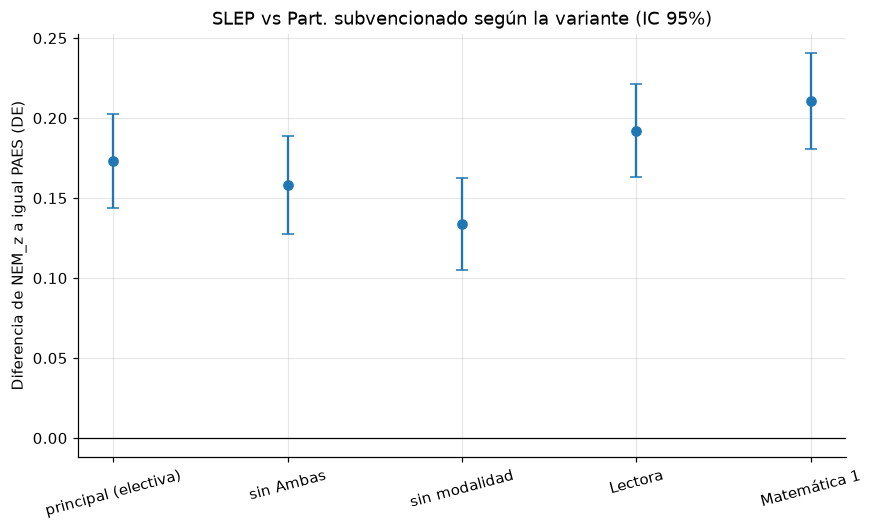

In [4]:
# 1.c Coeficiente de SLEP (vs Part. subvencionado) con IC 95% en cada
# variante.
slep = pd.DataFrame(slep).T
error = [slep['coef'] - slep['ic95_inf'], slep['ic95_sup'] - slep['coef']]
fig, ax = plt.subplots()
ax.errorbar(slep.index, slep['coef'], yerr=error, fmt='o', capsize=4)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='SLEP vs Part. subvencionado según la variante (IC 95%)',
       ylabel='Diferencia de NEM_z a igual PAES (DE)')
plt.xticks(rotation=15)
mostrar('sen_1c_slep')

**Interpretación.** La Hipótesis 1 es robusta:

- **SLEP** tiene una brecha condicional positiva frente a Part. subvencionado en las
  cinco variantes, entre **+0,13 y +0,21** DE, y frente a Municipal entre **+0,06 y
  +0,07**, con intervalos que nunca incluyen el 0.
- **Municipal** también queda sobre Part. subvencionado en todas las variantes
  (entre +0,07 y +0,14).
- **Part. pagado** cambia de signo según la prueba de referencia (-0,12 con
  Matemática 1, +0,05 con Lectora): su posición depende de qué prueba se use, así que
  no se puede concluir que tenga más o menos NEM a igual PAES.
- **Adm. delegada** cambia de signo al quitar la modalidad (+0,08 a -0,07): sus
  estudiantes son todos técnico-profesionales (y los de Part. pagado, todos
  científico-humanistas), así que su coeficiente y el de la modalidad se
  confunden. No se interpreta por separado.
- El ICC residual se mantiene entre 0,13 y 0,15.

## 2. Sensibilidad de la Hipótesis 2 sin el grupo Ambas

Se repite el resultado clave de `04_acceso_por_etapas`: con PAES baja, el OR de la
brecha condicional en la matrícula de los seleccionados, a igual puntaje ponderado.

In [5]:
# 2. OR de la brecha en matriculado | seleccionado, con PAES baja y a igual
# puntaje ponderado: con y sin el grupo Ambas.
CONTROLES_ACCESO = ('PAES_z + electiva + C(ANIO) + dependencia + decil'
                    ' + sexo + modalidad + ptje_100')
seleccionados = acceso[(acceso['seleccionado'] == 1)
                       & (acceso['tercil_paes'] == 'PAES baja')]
seleccionados = seleccionados.dropna(subset=['ptje_100'])
casos = [('con Ambas', seleccionados),
         ('sin Ambas', seleccionados[seleccionados['electiva'] != 'Ambas'])]
filas = {}
for nombre, d in casos:
    resultado = smf.logit('matriculado ~ brecha_cond + ' + CONTROLES_ACCESO,
                          d).fit(disp=False, cov_type='cluster',
                                 cov_kwds={'groups': d['RBD']})
    filas[nombre] = odds_ratios(resultado).loc['brecha_cond']
    filas[nombre]['n'] = len(d)
display(pd.DataFrame(filas).T.round(3))

,odds_ratio,ic95_inf,ic95_sup,valor_p,n
con Ambas,1.126,1.085,1.169,0.0,64905.0
sin Ambas,1.095,1.048,1.144,0.0,43469.0


**Interpretación.** Sin el grupo Ambas, el OR de la brecha en la matrícula de
los seleccionados con PAES baja, a igual puntaje ponderado, es 1,10 (IC 95%: 1,05 a
1,14), muy parecido al de la muestra completa (1,13). El resultado de la Hipótesis 2
no depende de incluir a quienes rindieron ambas electivas.

## 3. ¿Aporta un k-means de colegios?

El plan consideraba un k-means solo si entregaba perfiles de colegios que el modelo
no entrega. Para revisarlo se agrupan los colegios con al menos 10 estudiantes según
tres características estandarizadas: su brecha condicional media, su PAES media y su
decil medio.

In [6]:
# 3. k-means (k = 4) sobre perfiles de colegios con al menos 10 estudiantes,
# con las tres características estandarizadas.
colegios = datos.groupby('RBD').agg(
    n=('brecha_cond', 'size'),
    brecha_cond=('brecha_cond', 'mean'),
    paes_z=('PAES_z', 'mean'),
    decil_medio=('decil_medio_colegio', 'first'),
    dependencia=('dependencia', 'last'),
)
colegios = colegios[colegios['n'] >= 10]
perfil = colegios[['brecha_cond', 'paes_z', 'decil_medio']]
perfil_z = (perfil - perfil.mean()) / perfil.std()
_, colegios['grupo'] = kmeans2(perfil_z.to_numpy(), 4, seed=2026,
                               minit='++')

resumen = colegios.groupby('grupo')[['brecha_cond', 'paes_z',
                                     'decil_medio']].mean().round(2)
resumen['colegios'] = colegios['grupo'].value_counts()
print('Promedio de cada grupo:')
display(resumen)
print('Colegios por grupo y dependencia:')
display(pd.crosstab(colegios['grupo'], colegios['dependencia']))

Promedio de cada grupo:


,brecha_cond,paes_z,decil_medio,colegios
grupo,,,,
0,-0.27,-0.23,4.16,1022
1,0.25,-0.38,3.74,1129
2,0.14,0.25,5.92,550
3,-0.08,1.28,8.34,279


Colegios por grupo y dependencia:


dependencia,Part. subvencionado,Adm. delegada,Municipal,Part. pagado,SLEP
grupo,,,,,
0,662,45,265,13,37
1,585,25,439,1,79
2,347,0,34,166,3
3,10,0,1,268,0


**Decisión: el k-means se descarta.** Los cuatro grupos no entregan perfiles que
el modelo no tenga ya:

- Los grupos 2 y 3 son los colegios de mayor nivel socioeconómico (decil medio 5,9 y
  8,3), casi todos Part. pagado o Part. subvencionado: la misma información que dan
  la dependencia y la composición del colegio.
- Los grupos 0 y 1 son colegios de nivel socioeconómico parecido (decil medio cercano
  a 4) que se separan solo por su brecha media (-0,27 frente a +0,25). Esa diferencia
  entre colegios es justamente el **intercepto aleatorio** del modelo jerárquico, que
  la mide de forma continua y corrigiendo a los colegios pequeños, en vez de cortarla
  en dos grupos.
- Además, el resultado depende de decisiones arbitrarias (número de grupos y
  variables usadas) y sería más difícil de explicar que el modelo.

Que la mayoría de los colegios SLEP quede en el grupo 1 (brecha alta) es coherente
con la Hipótesis 1, pero no agrega nada al coeficiente del modelo.

## 4. Síntesis final

**Pregunta:** ¿cómo se asocian la dependencia del colegio y el nivel socioeconómico con
la brecha entre el NEM y la PAES, y cómo se relaciona esa brecha con el acceso a la
educación superior?

**Respuesta.**

1. **A igual PAES, el NEM mide casi lo mismo entre dependencias, pero no exactamente.**
   La brecha simple exageraba las diferencias (de -0,52 a +0,30 DE) por regresión a
   la media. En la brecha condicional quedan entre -0,13 y +0,12 DE (EDA). En el
   modelo jerárquico, respecto de Part. subvencionado: SLEP +0,17 y Municipal +0,11.
2. **SLEP es la excepción más robusta (Hipótesis 1).** A igual PAES, decil, sexo,
   modalidad y año, sus estudiantes tienen más NEM que los de Part. subvencionado
   (+0,13 a +0,21 DE según la variante) y que los municipales (+0,06 a +0,07), con o
   sin la composición del colegio, con pendiente aleatoria, con Lectora o Matemática
   1 y sin el grupo Ambas.
3. **El nivel socioeconómico del estudiante casi no cambia la brecha** (los deciles
   difieren entre +0,02 y +0,08 DE del decil 1). La **composición del colegio** sí se
   asocia: -0,05 DE por cada punto de decil medio (los colegios más acomodados ponen
   algo menos de NEM a igual PAES).
4. **La diferencia más grande es por sexo:** a igual PAES, las mujeres tienen 0,38 DE
   más de NEM (unos 53 puntos).
5. **El colegio importa:** cerca del 13% de la variación de la brecha condicional
   ocurre entre colegios (ICC exacto 0,130) y casi no la explican la dependencia ni
   la composición; dentro de cada dependencia los colegios varían mucho.
6. **Acceso (Hipótesis 2, en parte):** a igual PAES, más brecha se asocia a más
   acceso en todas las etapas, pero la ventaja en la selección es **mecánica** (el
   NEM sube el puntaje ponderado). Lo que queda a igual puntaje es pequeño: con PAES
   baja, los seleccionados con más brecha se matriculan algo más (OR 1,13; sin Ambas
   1,10).

**Limitaciones.**

- **Asociación, no causalidad:** los datos son observacionales; no permiten saber si
  las diferencias vienen de las prácticas de evaluación, de qué estudiantes llegan a
  cada colegio o de otros factores.
- **Solo cuatro procesos (2023-2026):** sirve para describir el periodo, no para hablar
  de una tendencia de inflación de notas; además, la PAES no es comparable entre años
  y por eso todo se estandariza dentro de cada año.
- **26% sin decil de ingreso:** se mantiene como categoría propia; si quienes no
  responden difieren de forma no observada, el efecto del decil podría estar
  subestimado.
- **Traspasos a SLEP:** 202 colegios cambian de dependencia en el periodo. En los
  modelos cada estudiante tiene la dependencia de su colegio en su año (un colegio
  traspasado cuenta como Municipal antes y como SLEP después); solo el análisis por
  colegio del EDA y el k-means usan la del año más reciente. Por eso la comparación
  de SLEP entre años mezcla colegios distintos.
- **Muestra de egresados recientes de educación regular:** los resultados no se
  aplican a quienes rinden años después de egresar, a la educación de adultos ni a
  quienes validan estudios.
- **Puntaje ponderado aproximado:** se usa el máximo entre las preferencias del
  estudiante, no el de la carrera a la que finalmente entra.
- **Variables que se confunden:** Part. pagado y la composición del colegio (no se
  puede comparar Part. pagado "a igual composición"), y Adm. delegada con la
  modalidad técnico-profesional.

**Posibles mejoras.**

- Usar datos de carreras y preferencias para entender por qué las mujeres, a igual
  PAES y brecha, quedan seleccionadas y se matriculan menos.
- Seguir a los colegios antes y después de su traspaso a SLEP para ver si la brecha
  cambia con la administración.
- Agregar procesos anteriores (PSU/PDT) para estudiar tendencias, con cuidado por el
  cambio de pruebas.
- Estimar modelos logísticos mixtos para el acceso y una pendiente aleatoria por
  dependencia.
- Simular cómo cambiaría el acceso con el nuevo Puntaje Ranking desde la admisión
  2028, que compara a cada estudiante con su propio colegio.

## 5. Fuentes y condiciones de uso de los datos

**Datos.** Ministerio de Educación, Centro de Estudios: datos abiertos de los procesos
de admisión 2023 a 2026 (Inscritos y puntajes, Socioeconómico, Postulación y
selección, y Matrícula), "Bases Públicas con MRUN", publicadas en
https://datosabiertos.mineduc.cl, con sus libros de códigos 2026 (en `docs/`).

**Anonimización.** Según los libros de códigos, cada estudiante se identifica solo con
el `MRUN`, un identificador anonimizado, y se eliminaron los registros con categoría
de género "no binario" porque eran pocos y podían identificarse, para cumplir con la
Ley 19.628 de protección de datos personales. Este proyecto no intenta identificar
personas, no publica datos individuales y no presenta rankings de colegios: los
colegios (`RBD`) se usan solo para agrupar a los estudiantes en el modelo.

**Condiciones de uso.** Los datos son públicos y anonimizados (cada estudiante se
identifica solo con el `MRUN`) y provienen del portal de datos abiertos del
Mineduc, que no publica una licencia explícita de reutilización. En enero de 2024, la Subsecretaría de Educación Superior
pidió a las universidades no usar los puntajes PAES que reciben por el Sistema de
Acceso para hacer rankings de colegios ni estudios públicos, por tratarse de datos
personales protegidos por la Ley 19.628 (BioBioChile, 3 de enero de 2024); esa
indicación se refiere a los datos identificados del Sistema de Acceso, no a las
bases públicas anonimizadas que usa este proyecto.

**Cifras de contexto.**

- **Promedios sobre 6,0:** el porcentaje de egresados con promedio sobre 6,0 pasó de
  20% a 41% entre 2011 y 2023, según cifras del Mineduc reportadas por BioBioChile
  (2025).
- **Reforma al Ranking 2028:** Resolución Exenta 10.886 de 2025 de la Subsecretaría
  de Educación Superior (Diario Oficial, 24 de octubre de 2025), que modifica la
  Resolución Exenta 5.250 de 2022: desde el proceso de admisión 2028 el Puntaje
  Ranking se calcula con la posición del estudiante en cada nivel de enseñanza media
  dentro de su establecimiento y modalidad, comparado con las tres generaciones
  anteriores, prescindiendo del valor nominal de las notas. La Resolución Exenta
  2.139 de 2026 (Diario Oficial, 5 de junio de 2026) ajusta ese cálculo según el año
  de egreso.